<a href="https://colab.research.google.com/github/mimaaiz08/Image_Generation_Using_GANs/blob/main/DCGAN_FashionMNIST_GAN_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Image Generation Using Generative Adversarial Networks (GANs)

A **GAN** consists of two neural networks trained against each other:

- **Generator (G):** turns random noise into a synthetic image.
- **Discriminator (D):** looks at an image and predicts whether it is real (from the dataset) or fake (made by G).

**Adversarial training:** D learns to tell real from fake, while G learns to fool D. As D improves, G is forced to produce more convincing images.

**Objectives**
1. Train a DCGAN on Fashion-MNIST to generate new 28×28 grayscale clothing images.
2. Visualize training progress (image grids and loss curves).
3. Build an interactive UI that uses the trained Generator.
4. Save and reload the models without retraining.

## 2. Setup
Only TensorFlow, NumPy, Matplotlib and ipywidgets are needed (all preinstalled in Colab). We check for a GPU and fix random seeds for reproducibility.

In [1]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow version:", tf.__version__)
if gpus:
    print("GPU detected:", gpus[0].name)
else:
    print("No GPU found. Training will run on CPU (slower).")
    print("Tip: Runtime > Change runtime type > T4 GPU.")

os.makedirs("outputs/grids", exist_ok=True)
os.makedirs("outputs/checkpoints", exist_ok=True)

TensorFlow version: 2.21.0
GPU detected: /physical_device:GPU:0


## 3. Dataset
Fashion-MNIST has 60,000 training images (28×28 grayscale, 10 clothing classes). Labels are not needed for a GAN.

**Preprocessing**
- Convert pixels from [0, 255] to **[-1, 1]**, matching the Generator's `tanh` output.
- Add a channel dimension so images have shape (28, 28, 1).
- Shuffle and batch the data with `tf.data`.

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training data shape: (60000, 28, 28, 1) | min/max: -1.0 1.0


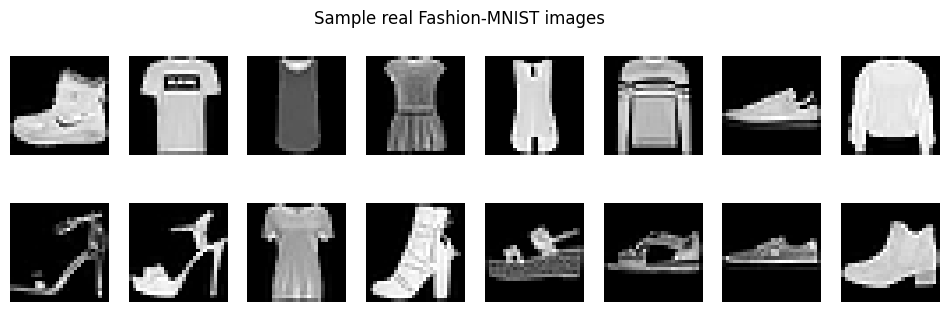

In [2]:
BATCH_SIZE = 128
NOISE_DIM = 100

(x_train, _), (_, _) = keras.datasets.fashion_mnist.load_data()
x_train = x_train.astype("float32")
x_train = (x_train - 127.5) / 127.5            # scale to [-1, 1]
x_train = np.expand_dims(x_train, axis=-1)     # (60000, 28, 28, 1)
print("Training data shape:", x_train.shape, "| min/max:", x_train.min(), x_train.max())

train_ds = (tf.data.Dataset.from_tensor_slices(x_train)
            .shuffle(60000, seed=SEED)
            .batch(BATCH_SIZE, drop_remainder=True)
            .prefetch(tf.data.AUTOTUNE))

# Show sample real images
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img in zip(axes.flat, x_train[:16]):
    ax.imshow(img.squeeze(), cmap="gray", vmin=-1, vmax=1)
    ax.axis("off")
plt.suptitle("Sample real Fashion-MNIST images")
plt.show()

## 4. Model Architecture

**Generator:** noise (100) → Dense → Reshape to 7×7×128 → two `Conv2DTranspose` layers (stride 2) upsample 7→14→28 → final `Conv2DTranspose` with `tanh` gives a 28×28×1 image. BatchNorm + LeakyReLU stabilize training.

**Discriminator:** two strided `Conv2D` layers (28→14→7) with LeakyReLU and Dropout, then Flatten and a single Dense unit. It outputs a **logit** (no sigmoid), so the loss uses `from_logits=True`.

In [3]:
def build_generator():
    return keras.Sequential([
        layers.Input(shape=(NOISE_DIM,)),
        layers.Dense(7 * 7 * 128, use_bias=False),
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Reshape((7, 7, 128)),
        layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False),  # 14x14
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(32, 5, strides=2, padding="same", use_bias=False),  # 28x28
        layers.BatchNormalization(),
        layers.LeakyReLU(0.2),
        layers.Conv2DTranspose(1, 5, strides=1, padding="same", activation="tanh"),
    ], name="generator")

def build_discriminator():
    return keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(64, 5, strides=2, padding="same"),   # 14x14
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Conv2D(128, 5, strides=2, padding="same"),  # 7x7
        layers.LeakyReLU(0.2),
        layers.Dropout(0.3),
        layers.Flatten(),
        layers.Dense(1),                                    # logit
    ], name="discriminator")

generator = build_generator()
discriminator = build_discriminator()
generator.summary()
discriminator.summary()

# Sanity check on shapes
test_img = generator(tf.random.normal([1, NOISE_DIM]), training=False)
print("Generator output shape:", test_img.shape)
print("Discriminator output shape:", discriminator(test_img, training=False).shape)

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 6272)           │       627,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 6272)           │        25,088 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 32)     │        51,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │           801 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 909,473 (3.47 MB)

 Trainable params: 896,737 (3.42 MB)

 Non-trainable params: 12,736 (49.75 KB)

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

Generator output shape: (1, 28, 28, 1)
Discriminator output shape: (1, 1)


## 5. Training

Each step:
1. Generate fake images from noise.
2. **Discriminator loss:** real images should score 1, fake images 0.
3. **Generator loss:** fake images should be scored as real (1) by D.

Two separate Adam optimizers (lr = 2e-4, beta_1 = 0.5) update G and D from their own gradients. Image grids use a **fixed noise** vector so progress is comparable across epochs. A Generator checkpoint is saved at selected epochs for the UI.

In [ ]:
EPOCHS = 100          # increase (e.g. 30-50) for better quality
SAVE_EVERY = 1       # save grid + generator checkpoint every N epochs

bce = keras.losses.BinaryCrossentropy(from_logits=True)
g_optimizer = keras.optimizers.Adam(2e-4, beta_1=0.5)
d_optimizer = keras.optimizers.Adam(2e-4, beta_1=0.5)

def discriminator_loss(real_logits, fake_logits):
    real_loss = bce(tf.ones_like(real_logits), real_logits)
    fake_loss = bce(tf.zeros_like(fake_logits), fake_logits)
    return real_loss + fake_loss

def generator_loss(fake_logits):
    return bce(tf.ones_like(fake_logits), fake_logits)

@tf.function
def train_step(real_images):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)
        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)
        g_loss = generator_loss(fake_logits)
        d_loss = discriminator_loss(real_logits, fake_logits)
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))
    d_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))
    return g_loss, d_loss

# Fixed noise for consistent progress grids
fixed_noise = tf.random.normal([16, NOISE_DIM], seed=SEED)

def save_grid(model, noise, path, title=None, show=False):
    imgs = model(noise, training=False).numpy()
    imgs = (imgs + 1) / 2.0                        # back to [0, 1]
    n = len(imgs)
    cols = 4 if n == 16 else min(n, 8)
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 1.6, rows * 1.6))
    for ax in np.array(axes).flat:
        ax.axis("off")
    for ax, img in zip(np.array(axes).flat, imgs):
        ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100)
    if show:
        plt.show()
    plt.close(fig)

g_loss_history, d_loss_history = [], []
saved_epochs = []

import time
start = time.time()
for epoch in range(1, EPOCHS + 1):
    g_losses, d_losses = [], []
    for batch in train_ds:
        g_l, d_l = train_step(batch)
        g_losses.append(float(g_l))
        d_losses.append(float(d_l))
    g_loss_history.append(np.mean(g_losses))
    d_loss_history.append(np.mean(d_losses))

    if epoch % SAVE_EVERY == 0 or epoch == EPOCHS:
        save_grid(generator, fixed_noise, f"outputs/grids/epoch_{epoch:03d}.png",
                  title=f"Epoch {epoch}")
        generator.save(f"outputs/checkpoints/generator_epoch_{epoch:03d}.keras")
        saved_epochs.append(epoch)

    print(f"Epoch {epoch:02d}/{EPOCHS} | G loss: {g_loss_history[-1]:.3f} | "
          f"D loss: {d_loss_history[-1]:.3f} | elapsed: {time.time()-start:.0f}s")

print("Training finished. Checkpoints saved for epochs:", saved_epochs)

Epoch 01/100 | G loss: 0.710 | D loss: 1.341 | elapsed: 20s
Epoch 02/100 | G loss: 0.779 | D loss: 1.269 | elapsed: 34s
Epoch 03/100 | G loss: 0.831 | D loss: 1.247 | elapsed: 47s
Epoch 04/100 | G loss: 0.789 | D loss: 1.295 | elapsed: 61s
Epoch 05/100 | G loss: 0.786 | D loss: 1.302 | elapsed: 75s
Epoch 06/100 | G loss: 0.785 | D loss: 1.306 | elapsed: 89s
Epoch 07/100 | G loss: 0.782 | D loss: 1.306 | elapsed: 103s
Epoch 08/100 | G loss: 0.784 | D loss: 1.310 | elapsed: 118s
Epoch 09/100 | G loss: 0.781 | D loss: 1.313 | elapsed: 132s
Epoch 10/100 | G loss: 0.788 | D loss: 1.311 | elapsed: 146s
Epoch 11/100 | G loss: 0.782 | D loss: 1.314 | elapsed: 161s
Epoch 12/100 | G loss: 0.785 | D loss: 1.315 | elapsed: 175s
Epoch 13/100 | G loss: 0.782 | D loss: 1.318 | elapsed: 189s
Epoch 14/100 | G loss: 0.783 | D loss: 1.319 | elapsed: 203s
Epoch 15/100 | G loss: 0.781 | D loss: 1.321 | elapsed: 218s
Epoch 16/100 | G loss: 0.776 | D loss: 1.325 | elapsed: 232s
Epoch 17/100 | G loss: 0.782 |

## 6. Results
Below are the generated grids (same fixed noise) at different epochs, followed by the loss curves.

In [ ]:
import matplotlib.image as mpimg

# Show grids from first, middle and last saved epochs
chosen = sorted(set([saved_epochs[0], saved_epochs[len(saved_epochs)//2], saved_epochs[-1]]))
fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5))
axes = np.atleast_1d(axes)
for ax, ep in zip(axes, chosen):
    ax.imshow(mpimg.imread(f"outputs/grids/epoch_{ep:03d}.png"))
    ax.axis("off")
plt.tight_layout()
plt.show()

def plot_losses():
    plt.figure(figsize=(7, 4))
    xs = range(1, len(g_loss_history) + 1)
    plt.plot(xs, g_loss_history, label="Generator loss", marker="o")
    plt.plot(xs, d_loss_history, label="Discriminator loss", marker="o")
    plt.xlabel("Epoch"); plt.ylabel("Loss")
    plt.title("DCGAN training losses")
    plt.legend(); plt.grid(alpha=0.3)
    plt.show()

plot_losses()

### Interpretation and Limitations
- **Early epochs:** images are blurry blobs; by later epochs, clothing shapes (shirts, shoes, bags) become recognizable.
- **Losses:** GAN losses do not decrease like normal classifier losses. A roughly balanced, slowly shifting pair of curves suggests neither network is dominating. A very low D loss with a rising G loss would mean D is winning.
- **Quality:** with only 10 epochs the images are rough and often have noisy textures. They should not be called realistic. More epochs improve quality.
- **Mode collapse:** the Generator may favor a few easy categories (e.g. shoes or bags) and produce repetitive outputs. Check the grids for this, since low loss alone does not rule it out.
- **No quantitative metric:** we judge quality visually only. Metrics such as FID would be needed for a rigorous evaluation.

## 7. Interactive UI
The widgets below load the **saved Generator checkpoints** and generate images from fresh random noise each click. If ipywidgets fails in your environment, run the Matplotlib fallback cell below it.

In [ ]:
try:
    import ipywidgets as widgets
    from IPython.display import display, clear_output
    UI_AVAILABLE = True
except Exception as e:
    print("ipywidgets unavailable, use the fallback cell below:", e)
    UI_AVAILABLE = False

_gen_cache = {}
def load_checkpoint(epoch):
    if epoch not in _gen_cache:
        _gen_cache[epoch] = keras.models.load_model(
            f"outputs/checkpoints/generator_epoch_{epoch:03d}.keras", compile=False)
    return _gen_cache[epoch]

if UI_AVAILABLE:
    title = widgets.HTML("<h2>Fashion Image Generator (DCGAN)</h2>"
                         "<p>Generates synthetic clothing images using the trained Generator. "
                         "Quality depends on the selected epoch.</p>")
    epoch_dd = widgets.Dropdown(options=saved_epochs, value=saved_epochs[-1],
                                description="Checkpoint:", style={"description_width": "90px"})
    n_slider = widgets.IntSlider(value=16, min=1, max=64, step=1,
                                 description="# Images:", style={"description_width": "90px"})
    gen_btn = widgets.Button(description="Generate new images", button_style="success",
                             icon="refresh")
    loss_btn = widgets.Button(description="Show training loss graph", button_style="info",
                              icon="line-chart")
    status = widgets.Label(value="Ready. Choose a checkpoint and click Generate.")
    out = widgets.Output()

    def on_generate(_):
        status.value = "Generating..."
        with out:
            clear_output(wait=True)
            model = load_checkpoint(epoch_dd.value)
            noise = tf.random.normal([n_slider.value, NOISE_DIM])
            save_grid(model, noise, None,
                      title=f"{n_slider.value} generated images (epoch {epoch_dd.value} checkpoint)",
                      show=True)
        status.value = f"Done: generated {n_slider.value} images from the epoch {epoch_dd.value} checkpoint."

    def on_loss(_):
        status.value = "Plotting loss graph..."
        with out:
            clear_output(wait=True)
            plot_losses()
        status.value = "Loss graph displayed."

    gen_btn.on_click(on_generate)
    loss_btn.on_click(on_loss)
    display(widgets.VBox([title, epoch_dd, n_slider,
                          widgets.HBox([gen_btn, loss_btn]), status, out]))

**Fallback (Matplotlib only):** run the next cell only if the widget UI above does not work.

In [ ]:
def generate_images(n=16, epoch=None):
    epoch = epoch or saved_epochs[-1]
    model = load_checkpoint(epoch)
    noise = tf.random.normal([n, NOISE_DIM])
    save_grid(model, noise, None, title=f"{n} generated images (epoch {epoch})", show=True)

# Example: generate_images(n=16, epoch=saved_epochs[-1])
# To see the losses: plot_losses()

## 8. Save and Reload
Both models are saved in the native Keras format (`.keras`). The Generator can then be reloaded and used without any retraining.

In [ ]:
generator.save("outputs/generator_final.keras")
discriminator.save("outputs/discriminator_final.keras")
print("Saved final Generator and Discriminator.")

# Reload the Generator and generate images without retraining
reloaded_generator = keras.models.load_model("outputs/generator_final.keras", compile=False)
save_grid(reloaded_generator, tf.random.normal([8, NOISE_DIM]), None,
          title="Images from reloaded Generator", show=True)

# Optional: download to your computer
# from google.colab import files
# !zip -r outputs.zip outputs
# files.download("outputs.zip")

## 9. Final Demonstration
16 new images generated from fresh random noise (not the fixed noise used during training).

In [ ]:
final_noise = tf.random.normal([16, NOISE_DIM])
save_grid(reloaded_generator, final_noise, "outputs/final_demo.png",
          title="Final demo: 16 newly generated images", show=True)

## Conclusion
We trained a DCGAN on Fashion-MNIST for a short schedule and used it to generate new 28×28 clothing images from random noise. The Generator learned the rough shapes of common clothing categories, and the loss curves show the adversarial balance between the two networks. Quality is limited by the small number of epochs and the small model: images are recognizable but imperfect, and some variety may be missing (possible partial mode collapse). Training longer, tuning hyperparameters, or using conditional GANs and FID evaluation would be natural next steps.